# **CENG 463 – Introduction to Machine Learning HW2**

## **TASK 1: BAG OF WORDS**

/tmp/ipykernel_302920/3313144138.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(vocab, rotation=45)
/tmp/ipykernel_302920/3313144138.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(vocab, rotation=45)
/tmp/ipykernel_302920/3313144138.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(vocab, rotation=45)


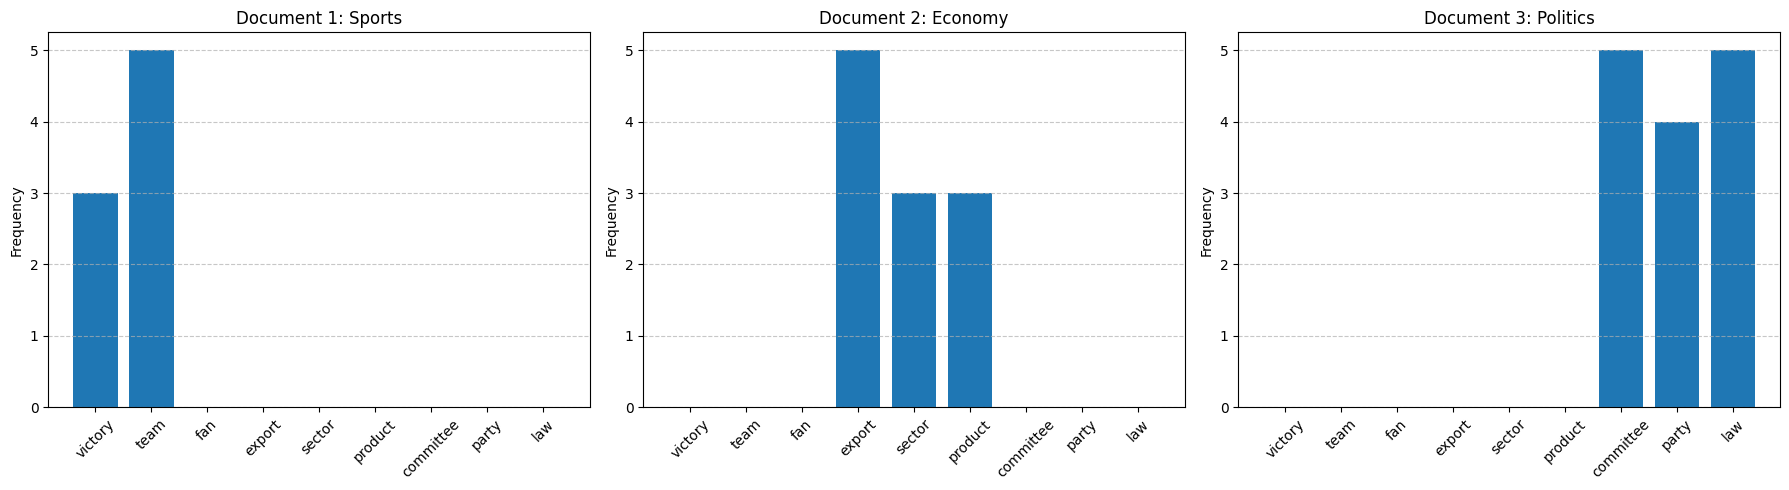

sports.txt Vector: [3 5 0 0 0 0 0 0 0]
economy.txt Vector: [0 0 0 5 3 3 0 0 0]
politics.txt Vector: [0 0 0 0 0 0 5 4 5]


In [ ]:
import numpy as np
import re
import matplotlib.pyplot as plt    

# Define vocabulary and files
vocab = ["victory", "team", "fan", "export", "sector", "product", "committee", "party", "law"]
files = ["sports.txt", "economy.txt", "politics.txt"]

#helper function to read files
def read_file(file_path):
    with open(file_path, 'r', encoding="utf-8") as file:
        return file.read().lower() #convert to lowercase for uniformity
    
#create frequency matrix
freq_matrix = np.zeros((len(files), len(vocab)), dtype=int) #rows: files, columns: vocab

#add frequencies to matrix
for i, file in enumerate(files):
    content = read_file(file)
    #TOKENIZE content in each document into words

    #re is the regex module in python
    #findall returns a list of all words matching the regex pattern
    #r indicates a raw string where backslashes are treated literally
    #\b matches word boundaries, \w+ matches one or more word characters (letters, digits, underscores)
    #\b\w+\b matches whole words
    words = re.findall(r'\b\w+\b', content)

    #count frequencies of each vocab word in the document for each document
    for j, word in enumerate(vocab):
        freq_matrix[i, j] = words.count(word)


#visualize frequency matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titles = ["Document 1: Sports", "Document 2: Economy", "Document 3: Politics"]

#create bar charts for each document
for i in range(freq_matrix.shape[0]):
    axes[i].bar(vocab, freq_matrix[i], color='#1f77b4')
    axes[i].set_title(titles[i])
    axes[i].set_xticklabels(vocab, rotation=45)
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

#printing vectors for project report(uncomment later)
# for i, f in enumerate(files):
#     print(f"{f} Vector: {freq_matrix[i]}")

## **TASK 2: TEXT CLASSIFICATION**

In [ ]:
# TO DO

       Word  Chi2 Statistic
5      free             9.0
8     smile             4.5
3  discount             3.0


### **Step 1: Chi-Square Feature Selection**

In [20]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2  

#define the dataset in the PDF
train_data = [
    "free free free buy discount combo pleasure",  # d1
    "free free free discount pleasure smile smile smile", # d2
    "cat mouse", # d3
    "cat cat dog dog dog dog", # d4
    "mouse" # d5
]
train_labels = [1, 1, 0, 0, 0]  # 1: spam, 0: not spam

#vectorize the dataset into count vectors for Chi-Square 
vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(train_data)#fit_transform creates the vocabulary and transforms the data into count vectors
feature_names = vectorizer.get_feature_names_out()#get the feature names (words) from the vectorizer

#compute Chi-Square statistics
chi2_stats, p_values = chi2(X_train, train_labels)

#display results in a DataFrame for better readability
chi2_df = pd.DataFrame({"Word": feature_names, "Chi2 Statistic": chi2_stats,})
chi2_df = chi2_df.sort_values(by="Chi2 Statistic", ascending=False) #sort by Chi2 statistic

#store and show top discriminative 3 words
top_3_discr= chi2_df.head(3)
print("Top 3 Discriminative Words based on Chi-Square Statistic:")
print(top_3_discr)

#NOTE for Report: 
#must manually show the calculation for 'free' in your PDF report as requested.

Top 3 Discriminative Words based on Chi-Square Statistic:
       Word  Chi2 Statistic
5      free             9.0
8     smile             4.5
3  discount             3.0


### **Step 2: TF-IDF Representation**

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

#define test data to include in full TF-IDF matrix
test_data = [
    "dog cat mouse cat", # d6
    "free free smile"    # d7
]

#combine train and test data for full TF-IDF matrix
all_data = train_data + test_data

#vectorize the combined dataset into TF-IDF vectors
vocab_list = top_3_discr["Word"].tolist() #get the top 3 discriminative words only their word names not the stats
tfidf_vectorizer = TfidfVectorizer(vocabulary=vocab_list) #use only top 3 discriminative words
X_tfidf = tfidf_vectorizer.fit_transform(all_data)

#create the table requested in the PDF
tfidf_df = pd.DataFrame(X_tfidf.toarray(), columns=vocab_list, index=[f"d{i+1}" for i in range(7)])
#display the TF-IDF table
print("TF-IDF for selected words:")
print(tfidf_df)

TF-IDF for selected words:
        free     smile  discount
d1  0.931664  0.000000  0.363321
d2  0.629845  0.736862  0.245621
d3  0.000000  0.000000  0.000000
d4  0.000000  0.000000  0.000000
d5  0.000000  0.000000  0.000000
d6  0.000000  0.000000  0.000000
d7  0.863169  0.504915  0.000000


### **Step 3: KNN Classification**

In [41]:
from sklearn.neighbors import KNeighborsClassifier

#prepare training and test sets
X_train_knn = X_tfidf[:5]  # first 5 documents for
y_train_knn = train_labels  # corresponding labels
X_test_knn = X_tfidf[5:]   # last 2 documents for testing

#initialize and train KNN classifier
knn_classifier = KNeighborsClassifier(n_neighbors=3)
knn_classifier.fit(X_train_knn, y_train_knn)

#predict labels for test documents
predicted_labels = knn_classifier.predict(X_test_knn)

#print predicted labels
print(f"Prediction for d6 ({test_data[0]}): {'spam' if predicted_labels[0] == 1 else 'not spam'}")
print(f"Prediction for d6 ({test_data[1]}): {'spam' if predicted_labels[1] == 1 else 'not spam'}")

# #for the report: Measure distances manually or output them here uncomment later
# distances, indices = KNeighborsClassifier.kneighbors(X_test_knn)
# print("\nDistances to nearest neighbors:", distances)
# print("Indices of nearest neighbors:", indices)

Prediction for d6 (dog cat mouse cat): not spam
Prediction for d6 (free free smile): spam


## **TASK 3: TOPIC MODELING WITH BERTOPIC**

### **Step 1: Dataset Creation**

In [56]:
from sklearn.datasets import fetch_20newsgroups

#fetch 20 newsgroups dataset
newsgroups_train = fetch_20newsgroups(remove=('headers', 'footers', 'quotes'))#remove headers, footers, quotes to focus on content only

#print all 20 category names
print("all 20 newsgroup categories:")
print(list(newsgroups_train.target_names))

print("\nwe will select 1: alt.atheism, 2: rec.autos, 3: talk.politics.mideast for our 3 categories.") 

#fetch only the selected 3 categories
selected_categories = ['alt.atheism', 'rec.autos', 'talk.politics.mideast']
newsgroups_train_selected = fetch_20newsgroups(subset='train', categories=selected_categories, remove=('headers', 'footers', 'quotes'))#remove headers, footers, quotes to focus on content only

all 20 newsgroup categories:
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

we will select 1: alt.atheism, 2: rec.autos, 3: talk.politics.mideast for our 3 categories.


### **Step 2: Model Training**

In [57]:
from bertopic import BERTopic

 #initialize BERTopic model
topic_model = BERTopic()

#train the model on the newsgroup data
topics, probs = topic_model.fit_transform(newsgroups_train_selected.data) #topics: assigned topic for each document, probs: probabilities for each topic assignment

#report the number of topics 
topic_info = topic_model.get_topic_info()
print(f"Number of topics identified: {len(topic_info)-1}") #subtract 1 for the 'outlier' topic
print(topic_info.head())  #display top topics


Number of topics identified: 18
   Topic  ...                                Representative_Docs
0     -1  ...  [This kind of argument cries for a comment...\...
1      0  ...  [I recently posted an article asking what kind...
2      1  ...  [I will try to answer some of Dorin's question...
3      2  ...  [\n\nIf you were omniscient, you'd know who ex...
4      3  ...  [Just kidding\n, hello testing\n\n\n, \nOh, th...

[5 rows x 5 columns]


### **Step 3: Topic Analysis**

In [ ]:
# TO DO

1638


### **Step 4: Visualization**

In [ ]:
# TO DO

### **Step 5: New Document Test**

In [ ]:
# TO DO